# Lesson 2 - Exercise 1: Quantifying KV Cache Memory Growth: Krithika's Solution


**Goal:** Empirically measure and analyze the growth in peak GPU memory consumption during LLM inference as the number of generated tokens increases, thereby quantifying the memory footprint of the Key-Value (KV) Cache.


**KSW NOTES:**: 
- you can use kv_cache by simply setting use_cache = True in model.generate(..., use_cache= True,...). **model.generate(...) will do all the heavy lifting for us**
- udacity asked to use the model :  llama/Llama-3.2-1B". But I used the model_name = "Qwen/Qwen2.5-0.5B", because it is more friendly on Nvidia GE Force RTX 3050
- As per the Udacity Starter Code , this only measures the peak memory. It demonstrates how Peak GPU memory increases due to KV cache (this is the bad part of using KV cache). But it is a tradeoff. The code does not measure the memory occupied by the kv tensors or anything, just measures only gpu memory
- I've added more code to measure of the latency and througput varies due to KV cache. Latency and througput usually improve due to the use of KV cache (this is the PROS)
- The latency measured here is average end-to-end time per generated token, including prompt prefill. It is not isolated decoding TPOT. The throughput is single-request generation throughput, and the peak memory measurement includes model weights and other allocations—not just the KV cache.


**KSW NOTES: actual tokens != generation length**
- What was observed is the actual tokens generated is not equal to generation length. The qwen model encounters the eos token much sooner and stops at 57 or 96 (depeding on which attention mechanism is being used, and if kv cache is on or off)


Attention Mechanism |	        Cache ON                |	      Cache OFF      |
--------------------| ----------------------------------| -----------------------|
SDPA	            |      At least 10,000 tokens       |	     57 tokens       |
Eager	            |       95 tokens	                |       126 tokens       |

- Hence you need to take care of this in benchmark configuration
```
    # ---------------------------------------------------
    # 3. Benchmark generation configuration
    # ---------------------------------------------------
    # Step1:  Disable EOS stopping so that the model generates the requested number of tokens for both cache modes.
    # Use a copy so the model's original configuration is not modified.
    # just disable eos stopping did not help
    # Step2: set the logits processor as well
```
**Other Relevant Code:KV cache on off results**
- using model "Qwen/Qwen2.5-0.5B": c4_llm_inference_optimize/lesson2_transformer_architecture_optimize/ksw_solution/L2E1a_quantify_kv_cache_growth_ksw_soln.ipynb
- using model "facebook/opt-125m" : c1_model_optimize_foundation/lesson1_intro_to_model_optimization/T1_latency_throughput/exercise1_latency_throughput_ksw_solution.ipynb

## 2. Imports and Configuration

### KSW Notes : Generation Length vs KV Cache
KV Cache grows with Total Sequence Length \
Total Sequence Length = Input Prompt Length + Generated Token Length (generation length) \
When you set the generation length = 50, you are setting the max generated tokesn to 50. \
But the output might not warrant 50 tokens. Example the output of what is 2+2 .The answer is 4, which might be just 1-2 tokens. \
And if the output doesnt consume all the generation length tokens in , the kv cache will not grow as expected
generation_lengths = [10, 20, 30, 50, 100, 200, 500]

### KV cache Memory formula
M_KV=2 * L *B *T * H_{kv} *D_h * S

1. KV cache memory formula
- L   : Number of transformer layers
- B   : Batch size
- T   : Total sequence length
- H_kv: Number of KV heads
- D_h :	Head dimension
- S   :	Bytes per element
- 2	   : Key cache + Value cache


In [1]:
import os
import torch
import time
import math
from transformers import AutoModelForCausalLM, AutoTokenizer
import gc # For garbage collection
import matplotlib.pyplot as plt

# --- Configuration ---
'''
os.environ["HF_HUB_OFFLINE"] = "1"
model_name = "/voc/shared/models/llama/Llama-3.2-1B"
'''

model_name = "Qwen/Qwen2.5-0.5B"
ATTENTION_IMPLEMENTATION = "sdpa"

device = "cuda" if torch.cuda.is_available() else "cpu"
if device == "cpu":
    print("WARNING: This exercise requires a CUDA-enabled GPU for meaningful memory measurements. Results on CPU will not reflect KV cache growth on GPU.")

# TODO: Determine appropriate dtype
if device == "cuda":
    if torch.cuda.is_bf16_supported():
        dtype = torch.bfloat16
        print("Using torch.bfloat16")
    else:
        dtype = torch.float16
        print("Using torch.float16 (bf16 not supported)")
else:
    dtype = torch.float32 # Default for CPU
    print("Using torch.float32 for CPU")

prompt = "The best way to optimize LLM inference is"

# TODO: Define a list of different max_new_tokens values to test.
generation_lengths = [10, 20, 30, 50, 100, 200, 500, 1000,2000,4000]
#generation_lengths = [10, 20, 30, 50, 100]

print(f"Device: {device}")
print(f"Model: {model_name}")
print(f"Prompt: '{prompt}'")
print(f"Generation lengths to test: {generation_lengths}")

/home/kssn/ksw_env/lib/python3.12/site-packages/torch/cuda/__init__.py:61: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Using torch.bfloat16
Device: cuda
Model: Qwen/Qwen2.5-0.5B
Prompt: 'The best way to optimize LLM inference is'
Generation lengths to test: [10, 20, 30, 50, 100, 200, 500, 1000, 2000, 4000]


## 2b Check what attention mechansisms are available for the model chosen

In [2]:
'''
import transformers
from transformers import AutoModelForCausalLM

print("Transformers:", transformers.__version__)

for impl in ["eager", "sdpa", "flash_attention_2", "flex_attention"]:
    try:
        model = AutoModelForCausalLM.from_pretrained(
            model_name ,
            attn_implementation=impl,
            torch_dtype="float16"
        )
        print(f"{impl}: SUPPORTED")
        del model
    except Exception as e:
        print(f"{impl}: NOT AVAILABLE")
        print(f"  {str(e)[:200]}")
'''

'\nimport transformers\nfrom transformers import AutoModelForCausalLM\n\nprint("Transformers:", transformers.__version__)\n\nfor impl in ["eager", "sdpa", "flash_attention_2", "flex_attention"]:\n    try:\n        model = AutoModelForCausalLM.from_pretrained(\n            model_name ,\n            attn_implementation=impl,\n            torch_dtype="float16"\n        )\n        print(f"{impl}: SUPPORTED")\n        del model\n    except Exception as e:\n        print(f"{impl}: NOT AVAILABLE")\n        print(f"  {str(e)[:200]}")\n'

## 3. Helper Function to Measure Peak Memory

In [3]:
def get_peak_gpu_memory_mb(device_to_check="cuda"):
    """Records the peak GPU memory allocated since the last reset for the specified device."""
    if torch.cuda.is_available() and device_to_check == "cuda":
        torch.cuda.synchronize() # Ensure all CUDA operations are complete
        # TODO: check the documentation https://docs.pytorch.org/docs/stable/cuda.html for function that can give peak memory
        peak_mem_bytes = torch.cuda.max_memory_allocated(device_to_check)
        return peak_mem_bytes / (1024 * 1024) # Convert to MB
    return 0 # Return 0 if not on CUDA or for CPU

## 4. Load Model and Tokenizer

In [4]:
print(f"\nLoading model and tokenizer for {model_name}...")
try:
    # TODO-Done: Load the tokenizer using AutoTokenizer.from_pretrained()
    tokenizer = AutoTokenizer.from_pretrained(model_name, use_fast=True)
    
    # TODO-Done: Set tokenizer.pad_token if it's None (e.g., tokenizer.pad_token = tokenizer.eos_token)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    # TODO-Done: Load the model using AutoModelForCausalLM.from_pretrained()
    #       Specify torch_dtype=dtype and attn_implementation="sdpa"
    model = AutoModelForCausalLM.from_pretrained(
        model_name,
        torch_dtype=dtype,
        trust_remote_code=False,
        low_cpu_mem_usage=True,
        attn_implementation=ATTENTION_IMPLEMENTATION
    )

    #TODO-Done: Move the model to the specified device (.to(device))
    model.to(device)

    # TODO-Done: Set the model to evaluation mode using model.eval()
    model.eval()

    print("Model and tokenizer loaded successfully.")
except Exception as e:
    print(f"Error loading model/tokenizer: {e}")
    # exit() # Consider exiting if loading fails


Loading model and tokenizer for Qwen/Qwen2.5-0.5B...
Model and tokenizer loaded successfully.


## 5. Test Configuration & Measurement Loop
## 6. Deliverables: Analysis and Reporting

In [5]:

import gc
import time
import math
import copy
import torch
import matplotlib.pyplot as plt

from transformers import LogitsProcessor, LogitsProcessorList


class SuppressEOS(LogitsProcessor):
    def __init__(self, eos_token_ids):
        if isinstance(eos_token_ids, int):
            eos_token_ids = [eos_token_ids]
        self.eos_token_ids = eos_token_ids

    def __call__(self, input_ids, scores):
        scores[:, self.eos_token_ids] = -float("inf")
        return scores


def run_and_plot_for_varied_lengths(use_cache=True):

    use_cache_string = f"(Use KV Cache = {use_cache})"

    peak_memory_results_mb = []
    delta_peak_memory_results_mb = []
    actual_tokens_generated_list = []
    generation_times = []
    latency_results_ms = []
    throughput_results = []

    print("\n--- Measuring KV Cache Performance",
          use_cache_string, "---")

    if device != "cuda" or model is None:
        print("Skipping: Model not loaded or CUDA unavailable.")
        return

    # ---------------------------------------------------
    # 1. Initial GPU memory measurement
    # ---------------------------------------------------
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize(device)
    torch.cuda.reset_peak_memory_stats(device)

    # Baseline: currently allocated GPU memory
    baseline_memory_mb = (
        torch.cuda.memory_allocated(device) / (1024 ** 2)
    )

    initial_peak_memory_mb = get_peak_gpu_memory_mb(device)

    print(
        f"Baseline GPU memory (model loaded): "
        f"{baseline_memory_mb:.2f} MB"
    )

    print(
        f"Initial peak memory (model loaded): "
        f"{initial_peak_memory_mb:.2f} MB"
    )

    # Dummy forward pass (warmup)
    with torch.no_grad():
        _ = model(
            torch.tensor([[0]], device=device),
            use_cache=False
        )

    torch.cuda.synchronize(device)

    one_forward_pass_peak_memory_mb = get_peak_gpu_memory_mb(device)

    print(
        f"Peak memory after 1 forward pass: "
        f"{one_forward_pass_peak_memory_mb:.2f} MB"
    )

    del _

    # ---------------------------------------------------
    # 2. Tokenize prompt
    # ---------------------------------------------------
    inputs = tokenizer(prompt, return_tensors="pt").to(device)

    num_input_tokens = inputs["input_ids"].shape[1]

    print(f"Input prompt tokens: {num_input_tokens}")

    # ---------------------------------------------------
    # 3. Benchmark generation configuration
    # ---------------------------------------------------
    # Disable EOS stopping so the model generates
    # the requested number of tokens.

    benchmark_config = copy.deepcopy(model.generation_config)

    benchmark_config.eos_token_id = None
    benchmark_config.forced_eos_token_id = None

    eos_ids = model.generation_config.eos_token_id

    if eos_ids is None:
        eos_ids = tokenizer.eos_token_id

    benchmark_logits_processor = LogitsProcessorList(
        [SuppressEOS(eos_ids)]
    )

    # ---------------------------------------------------
    # 4. Warm up the configuration being benchmarked
    # ---------------------------------------------------
    with torch.no_grad():
        warmup_output = model.generate(
            **inputs,
            max_new_tokens=3,
            use_cache=use_cache,
            do_sample=False,
            generation_config=benchmark_config,
            logits_processor=benchmark_logits_processor,
            pad_token_id=tokenizer.pad_token_id
        )

    del warmup_output

    torch.cuda.synchronize(device)

    # ---------------------------------------------------
    # 5. Generate tokens for varied lengths
    # ---------------------------------------------------
    for length in generation_lengths:

        print(f"\nGenerating {length} new tokens...")

        gc.collect()
        torch.cuda.empty_cache()
        torch.cuda.synchronize(device)

        # Reset peak statistics for this generation
        torch.cuda.reset_peak_memory_stats(device)

        try:
            # Start timer
            start_time = time.perf_counter()

            with torch.no_grad():
                output_ids = model.generate(
                    **inputs,
                    max_new_tokens=length,
                    use_cache=use_cache,
                    do_sample=False,
                    generation_config=benchmark_config,
                    logits_processor=benchmark_logits_processor,
                    pad_token_id=tokenizer.pad_token_id
                )

            # Wait for GPU operations to finish
            torch.cuda.synchronize(device)

            end_time = time.perf_counter()

            # -------------------------------------------
            # 6. Calculate metrics
            # -------------------------------------------

            # Total generation time
            gen_time = end_time - start_time

            # Actual tokens generated
            num_output_tokens = output_ids.shape[1]

            actual_new_tokens = (
                num_output_tokens - num_input_tokens
            )

            # Average latency per generated token
            avg_latency_ms = (
                gen_time * 1000 / actual_new_tokens
                if actual_new_tokens > 0
                else float("nan")
            )

            # Throughput
            throughput = (
                actual_new_tokens / gen_time
                if gen_time > 0 and actual_new_tokens > 0
                else float("nan")
            )

            # Peak GPU memory
            current_peak_memory_mb = get_peak_gpu_memory_mb(device)

            # NEW: Delta peak memory relative to baseline
            delta_peak_memory_mb = (
                current_peak_memory_mb - baseline_memory_mb
            )

            # -------------------------------------------
            # 7. Save results
            # -------------------------------------------
            actual_tokens_generated_list.append(actual_new_tokens)
            generation_times.append(gen_time)
            latency_results_ms.append(avg_latency_ms)
            throughput_results.append(throughput)
            peak_memory_results_mb.append(current_peak_memory_mb)
            delta_peak_memory_results_mb.append(delta_peak_memory_mb)

            # Print results
            print(f"  Actual new tokens: {actual_new_tokens}")
            print(f"  Peak GPU memory: {current_peak_memory_mb:.2f} MB")
            print(f"  Delta peak memory: {delta_peak_memory_mb:.2f} MB")
            print(f"  Generation time: {gen_time:.4f} seconds")
            print(f"  Average latency: {avg_latency_ms:.2f} ms/token")
            print(f"  Throughput: {throughput:.2f} tokens/sec")

            if actual_new_tokens != length:
                print(
                    f"  WARNING: Requested {length} tokens, "
                    f"but generated {actual_new_tokens}."
                )

            del output_ids

        except Exception as e:

            print(f"Error generating {length} tokens: {e}")

            actual_tokens_generated_list.append(0)
            generation_times.append(float("nan"))
            latency_results_ms.append(float("nan"))
            throughput_results.append(float("nan"))
            peak_memory_results_mb.append(float("nan"))
            delta_peak_memory_results_mb.append(float("nan"))

            # CUDA device-side assertions require a kernel restart.
            if "device-side assert" in str(e).lower():
                raise

    # ---------------------------------------------------
    # 8. Cleanup
    # ---------------------------------------------------
    del inputs

    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.synchronize(device)

    # ---------------------------------------------------
    # 9. Results summary table
    # ---------------------------------------------------
    print("\n--- Results Summary", use_cache_string, "---")
    print(f"Baseline GPU Memory: {baseline_memory_mb:.2f} MB\n")

    print(
        f"{'Max Tokens':>10} | "
        f"{'Actual Tokens':>13} | "
        f"{'Peak Mem (MB)':>13} | "
        f"{'Delta Peak (MB)':>15} | "
        f"{'Time (s)':>10} | "
        f"{'Latency (ms/tok)':>16} | "
        f"{'Throughput (tok/s)':>18}"
    )

    print("-" * 125)

    for i, requested_length in enumerate(generation_lengths):

        print(
            f"{requested_length:10d} | "
            f"{actual_tokens_generated_list[i]:13d} | "
            f"{peak_memory_results_mb[i]:13.2f} | "
            f"{delta_peak_memory_results_mb[i]:15.2f} | "
            f"{generation_times[i]:10.4f} | "
            f"{latency_results_ms[i]:16.2f} | "
            f"{throughput_results[i]:18.2f}"
        )

    # ---------------------------------------------------
    # 10. Filter valid results for plotting
    # ---------------------------------------------------
    valid_indices = [
        i for i in range(len(generation_lengths))
        if (
            actual_tokens_generated_list[i] > 0
            and math.isfinite(peak_memory_results_mb[i])
            and math.isfinite(delta_peak_memory_results_mb[i])
            and math.isfinite(latency_results_ms[i])
            and math.isfinite(throughput_results[i])
        )
    ]

    plot_tokens = [
        actual_tokens_generated_list[i]
        for i in valid_indices
    ]

    plot_memory = [
        peak_memory_results_mb[i]
        for i in valid_indices
    ]

    plot_delta_memory = [
        delta_peak_memory_results_mb[i]
        for i in valid_indices
    ]

    plot_latency = [
        latency_results_ms[i]
        for i in valid_indices
    ]

    plot_throughput = [
        throughput_results[i]
        for i in valid_indices
    ]

    # ---------------------------------------------------
    # 11. Return dictionary
    # ---------------------------------------------------
    results = {
        "use_cache": use_cache,
        "requested_lengths": list(generation_lengths),
        "actual_tokens": actual_tokens_generated_list,
        "baseline_memory_mb": baseline_memory_mb,
        "peak_memory_mb": peak_memory_results_mb,
        "delta_peak_memory_mb": delta_peak_memory_results_mb,
        "generation_times_s": generation_times,
        "latency_ms_per_token": latency_results_ms,
        "throughput_tokens_per_sec": throughput_results
    }

    if not plot_tokens:
        print("No valid results to plot.")
        return results

    # ---------------------------------------------------
    # 12. Plot 1: Peak GPU Memory
    # ---------------------------------------------------
    plt.figure(figsize=(10, 6))

    plt.plot(
        plot_tokens,
        plot_memory,
        marker="o",
        linestyle="-"
    )

    plt.title(
        f"Peak GPU Memory vs Generated Tokens\n"
        f"Model: {model_name}, {use_cache_string}"
    )

    plt.xlabel("Number of Actual New Tokens Generated")
    plt.ylabel("Peak GPU Memory (MB)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------
    # 13. Plot 2: Delta Peak GPU Memory
    # ---------------------------------------------------
    plt.figure(figsize=(10, 6))

    plt.plot(
        plot_tokens,
        plot_delta_memory,
        marker="o",
        linestyle="-"
    )

    plt.title(
        f"Delta Peak GPU Memory vs Generated Tokens\n"
        f"Model: {model_name}, {use_cache_string}"
    )

    plt.xlabel("Number of Actual New Tokens Generated")
    plt.ylabel("Delta Peak GPU Memory (MB)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------
    # 14. Plot 3: Average Latency
    # ---------------------------------------------------
    plt.figure(figsize=(10, 6))

    plt.plot(
        plot_tokens,
        plot_latency,
        marker="o",
        linestyle="-"
    )

    plt.title(
        f"Average Latency vs Generated Tokens\n"
        f"Model: {model_name}, {use_cache_string}"
    )

    plt.xlabel("Number of Actual New Tokens Generated")
    plt.ylabel("Average Latency (ms/token)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    # ---------------------------------------------------
    # 15. Plot 4: Throughput
    # ---------------------------------------------------
    plt.figure(figsize=(10, 6))

    plt.plot(
        plot_tokens,
        plot_throughput,
        marker="o",
        linestyle="-"
    )

    plt.title(
        f"Throughput vs Generated Tokens\n"
        f"Model: {model_name}, {use_cache_string}"
    )

    plt.xlabel("Number of Actual New Tokens Generated")
    plt.ylabel("Throughput (tokens/sec)")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    print("\nExercise Complete.", use_cache_string)

    return results


## 7a. Run and Plot for Different Generation LEngths: Use_Cache = use_kv_cache = True


--- Measuring KV Cache Performance (Use KV Cache = True) ---
Baseline GPU memory (model loaded): 950.18 MB
Initial peak memory (model loaded): 950.18 MB


Starting from v4.46, the `logits` model output will have the same type as the model (except at train time, where it will always be FP32)


Peak memory after 1 forward pass: 959.31 MB
Input prompt tokens: 9

Generating 10 new tokens...
  Actual new tokens: 10
  Peak GPU memory: 960.26 MB
  Delta peak memory: 10.08 MB
  Generation time: 0.2073 seconds
  Average latency: 20.73 ms/token
  Throughput: 48.25 tokens/sec

Generating 20 new tokens...
  Actual new tokens: 20
  Peak GPU memory: 960.38 MB
  Delta peak memory: 10.20 MB
  Generation time: 0.1886 seconds
  Average latency: 9.43 ms/token
  Throughput: 106.02 tokens/sec

Generating 30 new tokens...
  Actual new tokens: 30
  Peak GPU memory: 960.49 MB
  Delta peak memory: 10.32 MB
  Generation time: 0.2799 seconds
  Average latency: 9.33 ms/token
  Throughput: 107.17 tokens/sec

Generating 50 new tokens...
  Actual new tokens: 50
  Peak GPU memory: 960.73 MB
  Delta peak memory: 10.55 MB
  Generation time: 0.4657 seconds
  Average latency: 9.31 ms/token
  Throughput: 107.36 tokens/sec

Generating 100 new tokens...
  Actual new tokens: 100
  Peak GPU memory: 961.32 MB
  Del

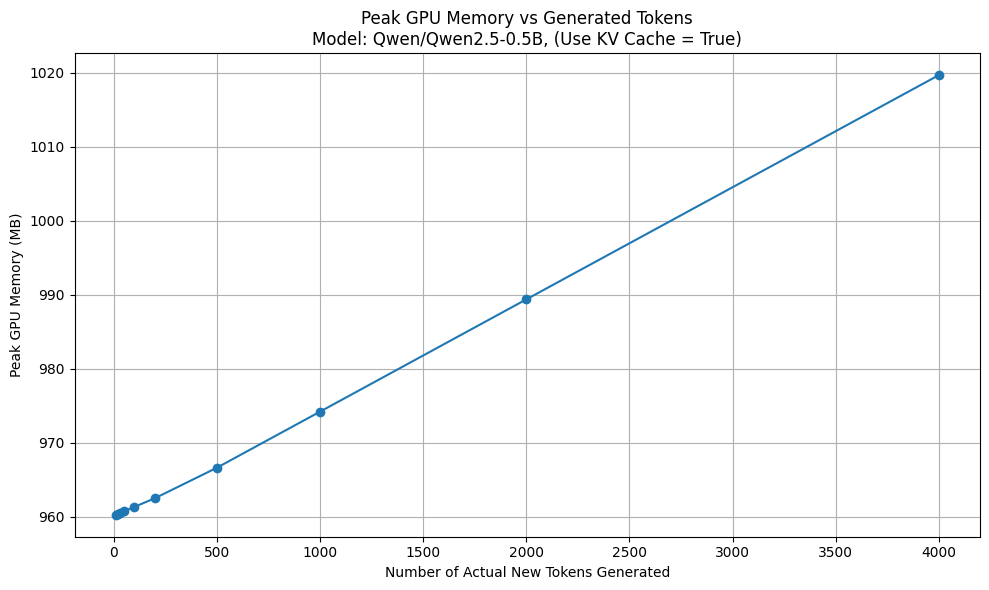

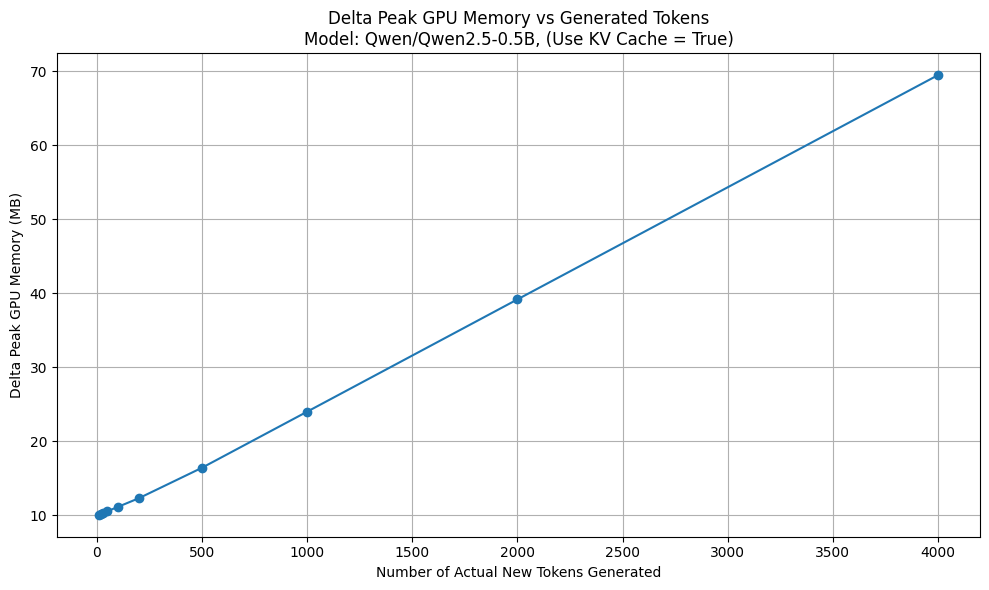

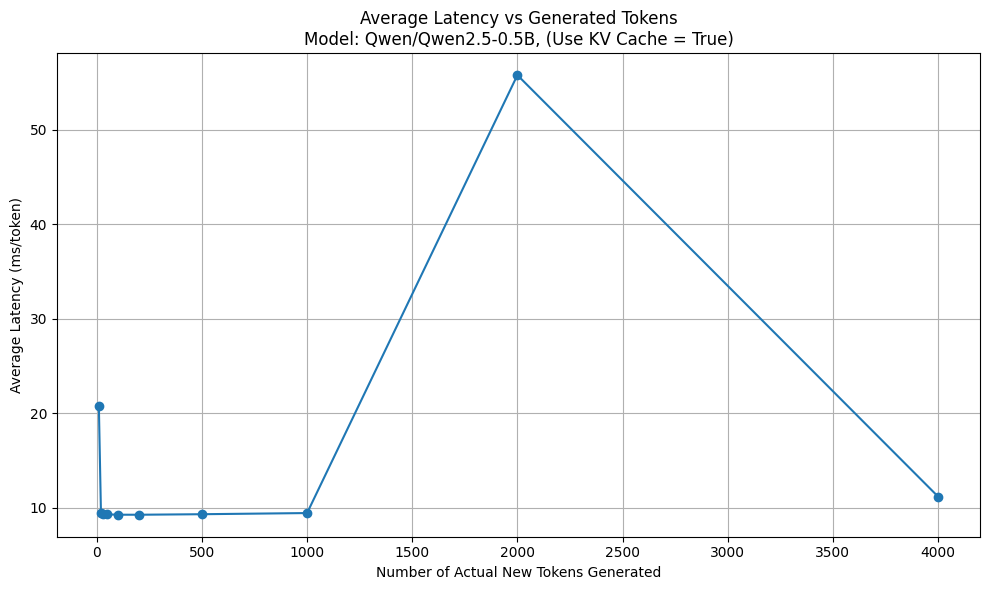

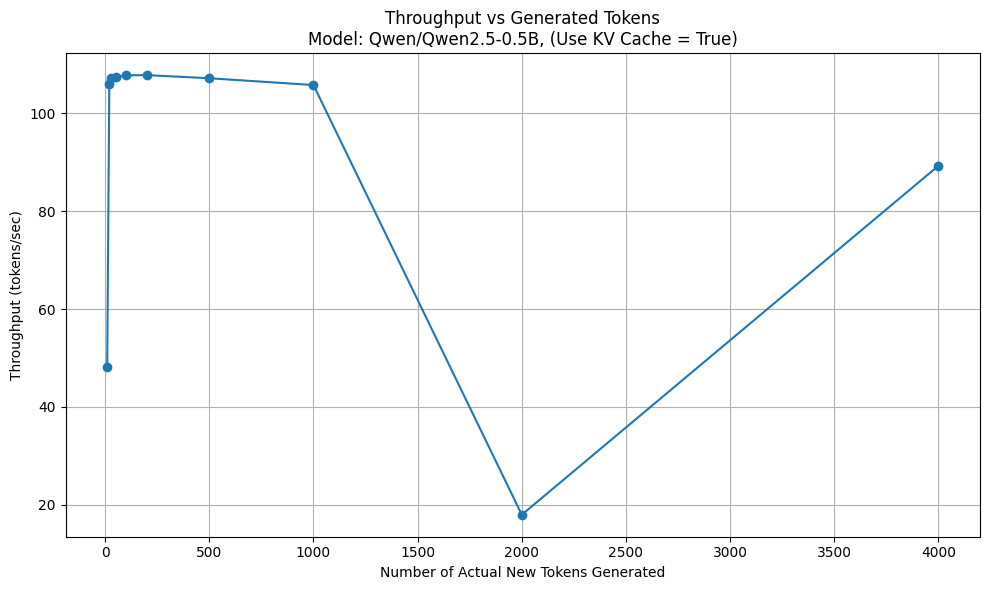


Exercise Complete. (Use KV Cache = True)


In [6]:
results_cache_on = run_and_plot_for_varied_lengths(
    use_cache=True
)

## 7b. Run and Plot for Different Generation LEngths: Use_Cache = use_kv_cache = False


--- Measuring KV Cache Performance (Use KV Cache = False) ---
Baseline GPU memory (model loaded): 958.30 MB
Initial peak memory (model loaded): 958.30 MB
Peak memory after 1 forward pass: 959.31 MB
Input prompt tokens: 9

Generating 10 new tokens...
  Actual new tokens: 10
  Peak GPU memory: 960.05 MB
  Delta peak memory: 1.75 MB
  Generation time: 0.1006 seconds
  Average latency: 10.06 ms/token
  Throughput: 99.41 tokens/sec

Generating 20 new tokens...
  Actual new tokens: 20
  Peak GPU memory: 960.10 MB
  Delta peak memory: 1.80 MB
  Generation time: 0.2005 seconds
  Average latency: 10.02 ms/token
  Throughput: 99.77 tokens/sec

Generating 30 new tokens...
  Actual new tokens: 30
  Peak GPU memory: 960.22 MB
  Delta peak memory: 1.91 MB
  Generation time: 0.4699 seconds
  Average latency: 15.66 ms/token
  Throughput: 63.84 tokens/sec

Generating 50 new tokens...
  Actual new tokens: 50
  Peak GPU memory: 960.91 MB
  Delta peak memory: 2.61 MB
  Generation time: 0.5128 seconds
  A

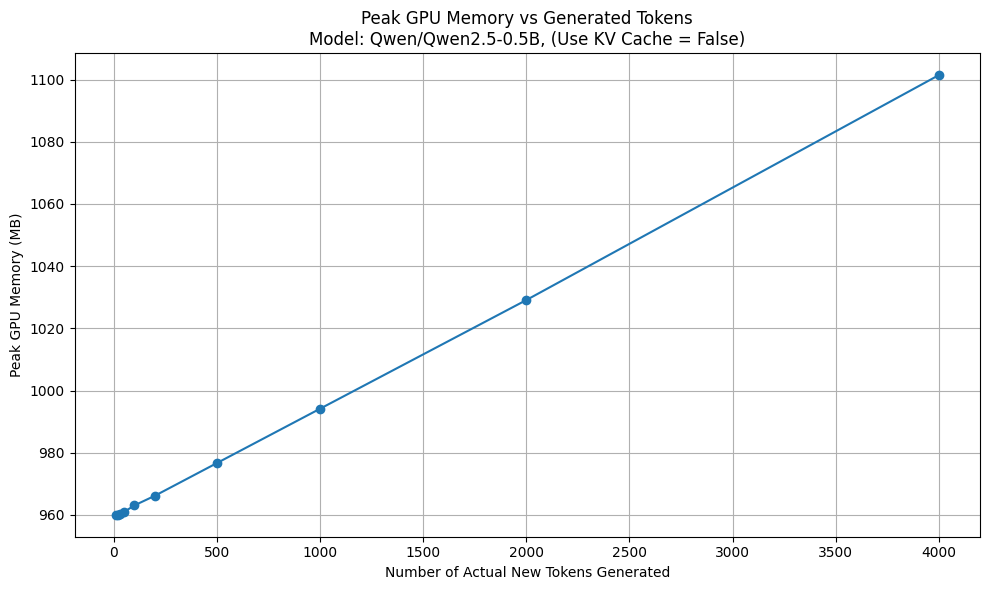

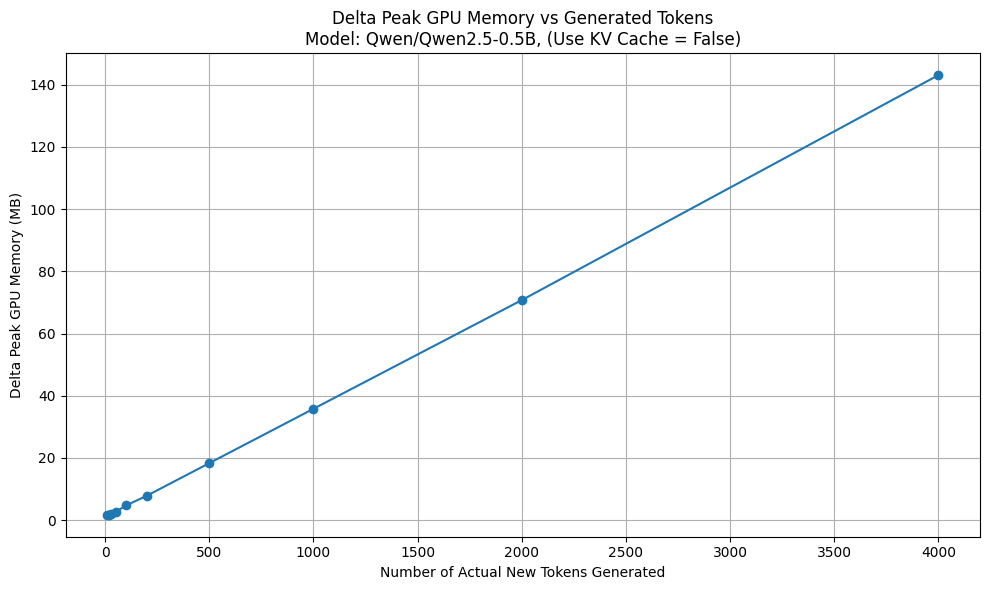

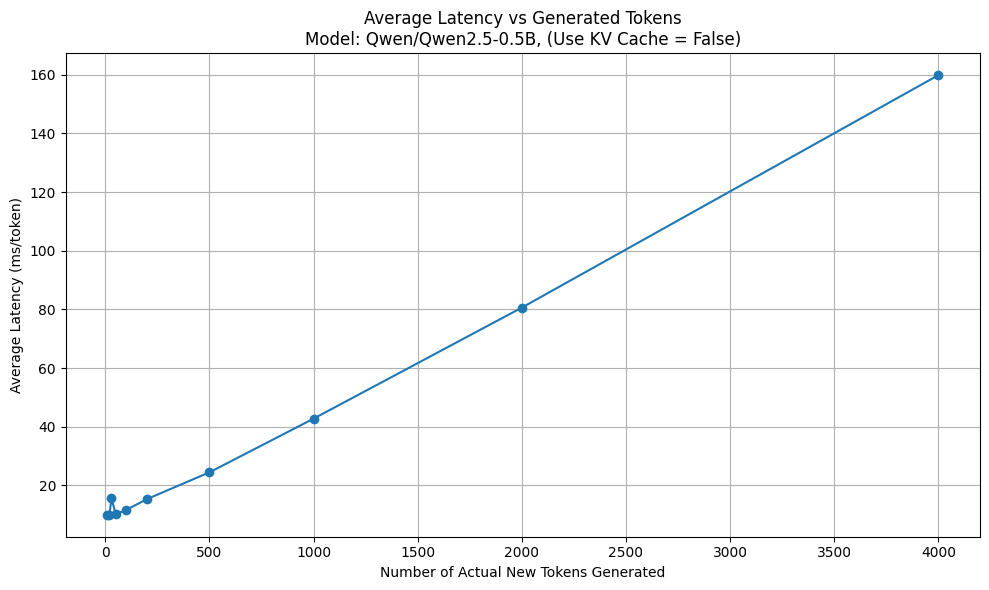

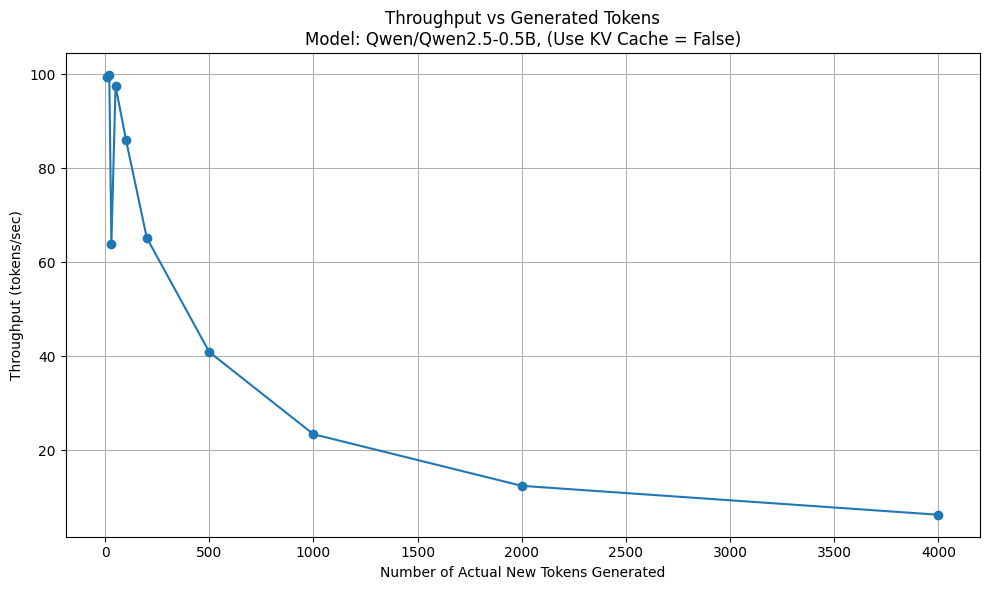


Exercise Complete. (Use KV Cache = False)


In [7]:
results_cache_off = run_and_plot_for_varied_lengths(
    use_cache=False
)


## 8a. Trend Analysis: Peak Memory Use Cache = True

**TODO-Done: Trend Analysis:** \
**Question1:** Describe the relationship you observe between 'Actual New Tokens' and 'Peak Memory (MB) during Gen'. \
Is it linear? Does it increase as expected? \
(You can also consider 'Peak Memory (MB) during Gen' - initial_peak_memory_mb to see the growth above the model size). \
**Answer:** Yes it is Linear


**TODO-Done: Estimate Memory per Token:**\
**Question2:** Calculate an estimate of how much *additional* memory the KV cache consumes per *actually generated new token*.
    - Select two data points from your results (e.g., generation for 50 tokens and 150 tokens).
    - Calculate ΔMemory = PeakMemory_LongerRun - PeakMemory_ShorterRun
    - Calculate ΔTokens = ActualTokens_LongerRun - ActualTokens_ShorterRun
    - Estimate MemoryPerToken = ΔMemory / ΔTokens (if ΔTokens > 0)
    - Print your chosen data points and the calculated memory per token.
**Answer:** \

--- Results Summary ---\


Max New Tokens  | Actual New Tokens | Peak Memory (MB) during Gen | Time (s)
--------------  | ----------------- | --------------------------  | ---------
             10 |                10 |                      960.26 |   0.1584
             20 |                20 |                      960.38 |   0.1811
             30 |                30 |                      960.49 |   0.2724
             50 |                50 |                      960.73 |   0.4507
            100 |               100 |                      961.32 |   0.8984
            200 |               200 |                      962.49 |   1.7980
            500 |               500 |                      966.60 |   4.6042
           1000 |              1000 |                      974.18 |   9.3464
           2000 |              2000 |                      989.35 |  19.6402

Token range	| ΔMemory   | ΔTokens | Memory/token
------------|-----------|---------|------------
10–500      | 6.34 MB   |	490   | 13.25 KiB
500–2000	| 22.75 MB  |  1500	  | 15.53 KiB


Interesting observation: The estimated memory per token is slightly higher for the longer generation range.\
This could reflect changes in cache allocation, memory alignment, or other temporary GPU allocations.\
It does not necessarily mean that the theoretical KV-cache size per token increases with sequence length.\
For a standard Transformer KV cache, memory per cached token is expected to remain approximately constant, even though total KV-cache memory grows linearly.


           
**TODO-Done: Practical Impact Discussion:**\
**Question3:** Briefly discuss how this growing KV cache memory footprint can become a limiting factor for generating  very long sequences, especially on GPUs with constrained VRAM. How does this relate to the concept of "context window limits" in practice (even if the model theoretically supports a large window)? \
**Answer:** \
Essentially : GPU Out of Memory (OOM) is the main concern. \
As the number of generated tokens increases, the KV cache grows, consuming more GPU memory. On GPUs with limited VRAM, this can eventually cause an Out of Memory (OOM) error. Therefore, even if a model theoretically supports a large context window, the available GPU memory may limit how many tokens can actually be processed or generated. \
One additional distinction:
- Theoretical context window: The maximum number of tokens the model is designed to handle.
- Practical context window: The number of tokens you can actually process given your GPU's available VRAM and inference configuration.
Remember that the context window includes both input prompt tokens and generated output tokens.

## 8b. Trend Analysis:  Peak Memory, Latency, Throughput: with and without KV Cache model  "Qwen/Qwen2.5-0.5B"



## Inference Benchmark Results

**Model:** `Qwen/Qwen2.5-0.5B`  
**Attention Implementation:** Eager

### 1a. KV Cache ON (`use_cache=True`):  model- Qwen/Qwen2.5-0.5B, Eager Attention, EOS Stopping Bypassed

| Max Tokens | Actual Tokens | Peak GPU Memory (MB) | Delta Peak (MB) | Total Latency (s) | Latency (ms/token) | Throughput (tokens/s) |
|-----------:|--------------:|---------------------:|----------------:|------------------:|-------------------:|----------------------:|
| 10 | 10 | 960.26 | 10.08 | 0.1753 | 17.53 | 57.04 |
| 20 | 20 | 960.38 | 10.20 | 0.2140 | 10.70 | 93.45 |
| 30 | 30 | 960.49 | 10.32 | 0.3104 | 10.35 | 96.64 |
| 50 | 50 | 960.73 | 10.55 | 0.5135 | 10.27 | 97.37 |
| 100 | 100 | 961.32 | 11.14 | 1.0311 | 10.31 | 96.98 |
| 200 | 200 | 962.49 | 12.31 | 2.2215 | 11.11 | 90.03 |
| 500 | 500 | 966.66 | 16.49 | 5.3126 | 10.63 | 94.12 |
| 1000 | 1000 | 974.31 | 24.13 | 10.8547 | 10.85 | 92.13 |
| 2000 | 2000 | 989.60 | 39.42 | 23.3447 | 11.67 | 85.67 |
| 4000 | 4000 | 1020.17 | 69.99 | 49.6645 | 12.42 | 80.54 |

### 1b. KV Cache Disabled (`use_cache=False`): :  model- Qwen/Qwen2.5-0.5B, Eager Attention, EOS Stopping Bypassed

**Baseline GPU Memory:** 958.30 MB

| Max Tokens | Actual Tokens | Peak GPU Memory (MB) | Delta Peak (MB) | Total Latency (s) | Latency (ms/token) | Throughput (tokens/s) |
|-----------:|--------------:|---------------------:|----------------:|------------------:|-------------------:|----------------------:|
| 10 | 10 | 960.05 | 1.75 | 0.1131 | 11.31 | 88.44 |
| 20 | 20 | 960.10 | 1.80 | 0.2220 | 11.10 | 90.10 |
| 30 | 30 | 960.22 | 1.92 | 0.3339 | 11.13 | 89.84 |
| 50 | 50 | 960.92 | 2.62 | 0.5659 | 11.32 | 88.35 |
| 100 | 100 | 963.05 | 4.75 | 1.2913 | 12.91 | 77.44 |
| 200 | 200 | 966.94 | 8.64 | 3.4546 | 17.27 | 57.89 |
| 500 | 500 | 999.41 | 41.10 | 15.3165 | 30.63 | 32.64 |
| 1000 | 1000 | 1107.97 | 149.67 | 65.9645 | 65.96 | 15.16 |
| 2000 | 2000 | 1528.47 | 570.17 | 386.8837 | 193.44 | 5.17 |
| 4000 | 0 | N/A | N/A | N/A | N/A | N/A |





Notice in the tables above
- latency and throughput are better kv cache is used. Although it has only marginally improved until 2K tokens. Maybe we should be generating 10K, 20K tokens to see the difference
- CONTRARY TO EXPECTATION, Peak memory is more when KV Cache is Off (it should have been higher when Kv Cache is on due to the caching)
- KV Cache off:
- 2000 tokens has , taken  387 seconds = 6-7 minutes. while with kv cache on it took only 23 seconds
- 4000 tokens is cuda out of memory in the current run.
- In a previous run 4000 tokens took 2271 seconds thats almost 35-40 minutes ! wherease with kv cache on it took only 48 seconds ! ,

**Question: Why is Peak Memory more when KV Cache is Off. This is not as per expectation ?** \
- This is actually one of the most interesting results from your experiment.
- Memory usage includes model weights, the growing KV cache, and temporary attention computations.
- KV CACHE ON:  KV-cache storage grows linearly with sequence length. (For a standard decoder with fixed batch size). You save the attention computation with Quadratic growth though
- KV caching OFF: you save memory by not storing previous K/V vectors, but you use much more temporary GPU memory during computation of attention scores which grows quadratically with sequence length (because the model repeatedly processes the entire growing sequence.)
- For a Sequence length N and Embedding Dimension E. Attention MAtrix size is Q*KT*V where Q :(N,d) ,  K :(N,d),  V :(N,d). N = sequence lenght, d = embedding dimension
  - Q*Kt : Matrix(N,d) * Matrix(d*N) = Matrix(N*N) , Complexity = O(N*d*N) = d*O(N*N) because only sequence length N varies. d is embedding dimension which is fixed
  - softmax(Q*Kt/sqrt(dk)) works on = Matrix(N*N) , Complexity = O(N*N)'
  - softmax(Q*Kt/sqrt(dk))*V = Matrix(N*N) * Matrix(N*d) = Matrix(N*d), Complexity = O(N*N*d) = d*O(N*N)
  - Total attention complexity is d*O(N*N)+ O(N*N)+ d*O(N*N) = (2d+1)O(N*N) ~= **O(N*N) i.e quadratic**

**Look at the additional peak memory above your approximately 960 MB baseline:** \
This was for one of the previous runs

| Generated Tokens | Cache ON Increase | Cache OFF Increase |
|-----------------:|------------------:|-------------------:|
| 500              | 16.7 MB            | 39.4 MB            |
| 1,000            | 14.3 MB           | 148.0 MB           |
| 2,000            | 29.6 MB           | 568.8 MB           |
| 4,000            | 60.2 MB           | 2,216.7 MB         |
   

Notice what happens when you double the sequence length from 2,000 to 4,000:
- Cache ON: Extra memory roughly doubles.
- Cache OFF: Extra memory grows by almost four times.
That's a strong indication that your cache-OFF path is allocating tensors whose memory scales approximately with \(T^2\), consistent with materialized attention matrices.
**EAGER ATTENTION**
It's not proof of exactly which tensors dominate the peak, but it matches the expected behavior of eager attention.
With eager attention, this full attention-score matrix is typically materialized. With SDPA, memory behavior depends on which attention kernel PyTorch selects.




## Qwen2.5-0.5B — SDPA Attention Benchmark

**Model:** `Qwen/Qwen2.5-0.5B`  
**Attention Implementation:** `SDPA`

### 1. KV Cache = True

**Baseline GPU Memory:** 950.18 MB

| Max Tokens | Actual Tokens | Peak Mem (MB) | Delta Peak (MB) | Time (s) | Latency (ms/tok) | Throughput (tok/s) |
|---:|---:|---:|---:|---:|---:|---:|
| 10 | 10 | 960.26 | 10.08 | 0.2073 | 20.73 | 48.25 |
| 20 | 20 | 960.38 | 10.20 | 0.1886 | 9.43 | 106.02 |
| 30 | 30 | 960.49 | 10.32 | 0.2799 | 9.33 | 107.17 |
| 50 | 50 | 960.73 | 10.55 | 0.4657 | 9.31 | 107.36 |
| 100 | 100 | 961.32 | 11.14 | 0.9278 | 9.28 | 107.78 |
| 200 | 200 | 962.49 | 12.31 | 1.8549 | 9.27 | 107.82 |
| 500 | 500 | 966.60 | 16.43 | 4.6649 | 9.33 | 107.18 |
| 1000 | 1000 | 974.18 | 24.00 | 9.4522 | 9.45 | 105.80 |
| 2000 | 2000 | 989.35 | 39.17 | 111.5026 | 55.75 | 17.94 |
| 4000 | 4000 | 1019.66 | 69.48 | 44.7977 | 11.20 | 89.29 |

### 2. KV Cache = False

**Baseline GPU Memory:** 958.30 MB

| Max Tokens | Actual Tokens | Peak Mem (MB) | Delta Peak (MB) | Time (s) | Latency (ms/tok) | Throughput (tok/s) |
|---:|---:|---:|---:|---:|---:|---:|
| 10 | 10 | 960.05 | 1.75 | 0.1006 | 10.06 | 99.41 |
| 20 | 20 | 960.10 | 1.80 | 0.2005 | 10.02 | 99.77 |
| 30 | 30 | 960.22 | 1.91 | 0.4699 | 15.66 | 63.84 |
| 50 | 50 | 960.91 | 2.61 | 0.5128 | 10.26 | 97.50 |
| 100 | 100 | 963.03 | 4.73 | 1.1625 | 11.62 | 86.02 |
| 200 | 200 | 966.16 | 7.85 | 3.0698 | 15.35 | 65.15 |
| 500 | 500 | 976.64 | 18.34 | 12.2366 | 24.47 | 40.86 |
| 1000 | 1000 | 994.12 | 35.81 | 42.7673 | 42.77 | 23.38 |
| 2000 | 2000 | 1029.07 | 70.77 | 161.2493 | 80.62 | 12.40 |
| 4000 | 4000 | 1101.42 | 143.11 | 639.4896 | 159.87 | 6.25 |


## Aside, check when is the stopping with and without cache i.e when is the eos generated

In [8]:
inputs = tokenizer(prompt, return_tensors="pt").to(device)
prompt_len = inputs["input_ids"].shape[1]

with torch.inference_mode():
    output_on = model.generate(
        **inputs,
        max_new_tokens=100,
        use_cache=True,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id
    )

    output_off = model.generate(
        **inputs,
        max_new_tokens=100,
        use_cache=False,
        do_sample=False,
        pad_token_id=tokenizer.pad_token_id
    )

tokens_on = output_on[0, prompt_len:].tolist()
tokens_off = output_off[0, prompt_len:].tolist()

print("Cache ON generated:", len(tokens_on))
print("Cache OFF generated:", len(tokens_off))

print("EOS token:", tokenizer.eos_token_id)
print("Cache OFF last token:", tokens_off[-1])
print("Cache OFF ended with EOS:",
      tokens_off[-1] == tokenizer.eos_token_id)

first_difference = next(
    (i for i, (a, b) in enumerate(zip(tokens_on, tokens_off))
     if a != b),
    None
)

print("First differing token position:", first_difference)

Cache ON generated: 100
Cache OFF generated: 57
EOS token: 151643
Cache OFF last token: 151643
Cache OFF ended with EOS: True
First differing token position: 22
